In [64]:
#import the necessary libraries 

#matplotlib
import matplotlib.pyplot as plot
import matplotlib.image as image

#numpy
import numpy as np

#scipy
import scipy
from scipy import ndimage

#scikit image
from skimage import io
from skimage.transform import rescale, resize, downscale_local_mean
from skimage.color import rgb2gray, rgb2hsv
from skimage.filters import threshold_otsu
from PIL import Image
import cv2
from skimage import measure


In [65]:
#we have also imported and used the code from the file that was given in the previous lab
import Image_formats_and_conversions as tools

In [66]:
#Reading the Image
img = image.imread('landscape.jpg')

RGB images can take 3 values for each pixel. Each of these values represents one of the channels of RGB color mode (red,green and blue respectively). In order to be able to see and plot the chromatic channels of an RGB image we first have to extract the values of each channel (R, G, B). 

In [67]:
#extracting the R,G,B channels

# Red channel
r = img[:, :, 0]

# Green channel
g = img[:, :, 1]

# Blue channel
b = img[:, :, 2]

Plotting the chromatic channels of our image in a 2X2 figure. In the figure are being included: the original image, red channel, green channel and blue channel.  

Text(0.5, 1.0, 'Blue Channel')

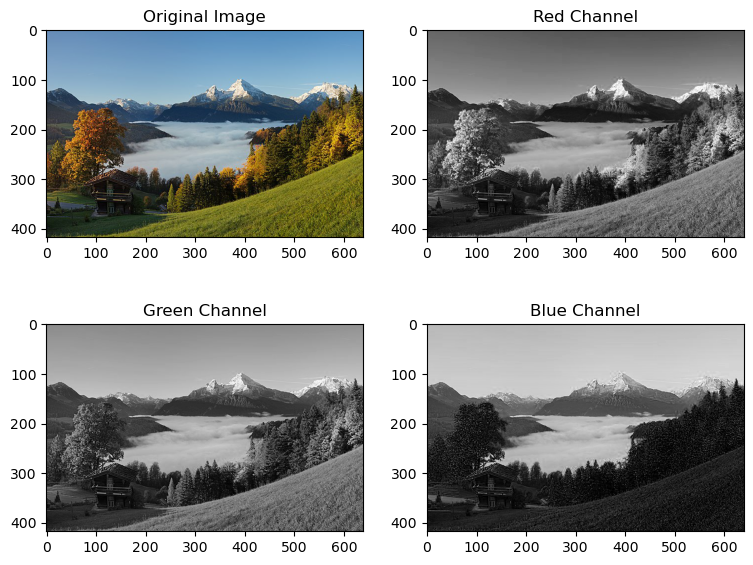

In [68]:
figure1 = plot.figure(2, figsize=(9,7))

subplot1 = plot.subplot(2,2,1)
plot.imshow(img)
subplot1.set_title('Original Image')

subplot1 = plot.subplot(2,2,2)
plot.imshow(r, cmap="gray")
subplot1.set_title('Red Channel')

subplot1 = plot.subplot(2,2,3)
plot.imshow(g, cmap="gray")
subplot1.set_title('Green Channel')

subplot1 = plot.subplot(2,2,4)
plot.imshow(b, cmap="gray")
subplot1.set_title('Blue Channel')

Regarding the next step, in order to plot the chromatic channels of the HSV (hue, saturation, value) we have to convert the RGB image to HSV. Furthermore, same as before, in order to be able to see and plot the chromatic HSV channels of the image (after the image convertion to HSV) we have to extract each channel (H,S,V)  

In [69]:
#converting the RGB image to HSV
hsv_image = rgb2hsv(img)

#extracting the H,S,V channels

# Hue channel
h = hsv_image[:, :, 0]

# Saturation channel
s = hsv_image[:, :, 1]

# Value channel
v = hsv_image[:, :, 2]

Plotting the chromatic channels of our image in a 2X2 figure. In the figure are being included: the original image, hue channel, saturation channel and value channel.  

Text(0.5, 1.0, 'Value Channel')

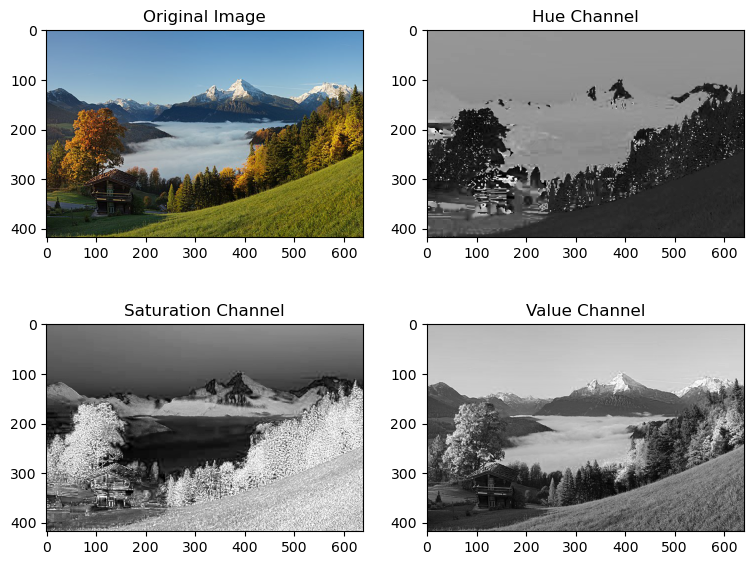

In [70]:
figure2 = plot.figure(2, figsize=(9,7))

subplot2 = plot.subplot(2,2,1)
plot.imshow(img)
subplot2.set_title('Original Image')

subplot2 = plot.subplot(2,2,2)
plot.imshow(h, cmap="gray")
subplot2.set_title('Hue Channel')

subplot2 = plot.subplot(2,2,3)
plot.imshow(s, cmap="gray")
subplot2.set_title('Saturation Channel')

subplot2 = plot.subplot(2,2,4)
plot.imshow(v, cmap="gray")
subplot2.set_title('Value Channel')

In [71]:
#Regarding the Grayscale image

#converting the RGB image to grayscale image
Grayscale__image = rgb2gray(img) # scikit image function

# Greyscale Image Normalization
normalized_grayscale_image = (Grayscale__image * 255).round().astype(np.uint8)


While threshold_otsu is expected to work correctly only for grayscale images, we are converting the normalized grayscale image into binary. 

In [72]:
#Regarding the Binary image (with the usage of threshold)

#converting the normalized grayscale image to binary

# Generate otsu threshold
threshold = threshold_otsu(normalized_grayscale_image)
# Apply threshold
Binary_image = normalized_grayscale_image > threshold
# Convert to integer
Binary_image=Binary_image.astype(int)


Plotting the original image, the images we just converted (grayscale and binary) as well as the threshold histogram that we used in order to convert the image into binary. 

Text(0.5, 1.0, 'Threshold Histogram')

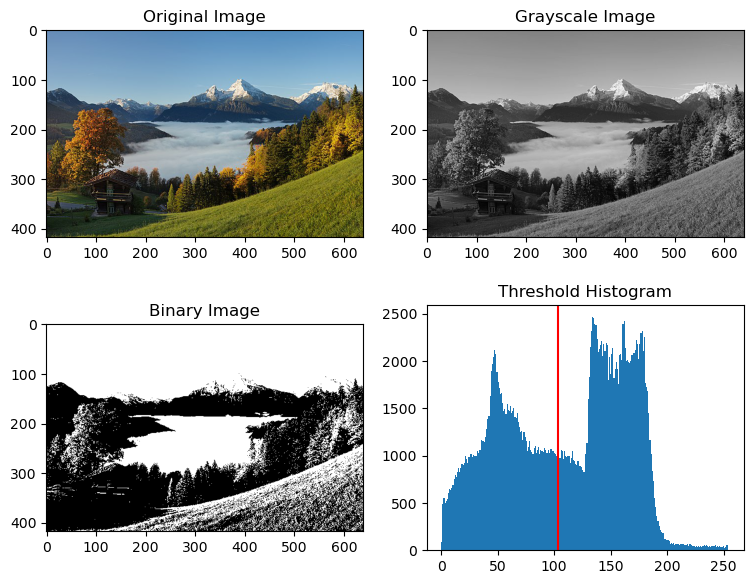

In [73]:
figure3 = plot.figure(2, figsize=(9,7))

subplot3 = figure3.add_subplot(2,2,1)
plot.imshow(img)
subplot3.set_title('Original Image')

subplot3 = figure3.add_subplot(2,2,2)
plot.imshow(Grayscale__image, cmap="gray")
subplot3.set_title('Grayscale Image')

subplot3 = figure3.add_subplot(2,2,3)
plot.imshow(Binary_image, cmap="gray")
subplot3.set_title('Binary Image')

subplot3 = figure3.add_subplot(2,2,4)
plot.hist(normalized_grayscale_image.ravel(), bins=256)
plot.axvline(threshold, color='r')
subplot3.set_title('Threshold Histogram')

In the above figure we have plotted the original image (as given), the grayscale image, which practically is the original image depicted to shades of gray, as well as the binary image which is a monochromatic image that consists of pixels that can have one of exactly two colors, black and white. (This means that each pixel is stored as a single bit, 0 or 1.) We have achieved converting the grayscale image to binary with the use of the threshold. The last image is referred to the threshold histogram. An “optimal” threshold is depicted, marked by a red line in the histogram above.

In [74]:
#rescaling the grayscale image with smooth edges (scale factor = 0.4)
smoothed_image = rescale(normalized_grayscale_image, 0.4, anti_aliasing=True)

#resizing the grayscale image into 250x250
newsize = (250, 250)
resized_image = cv2.resize(normalized_grayscale_image, newsize)

#rotating the resized image 90 degrees counterclockwise
rotated_image = ndimage.rotate(resized_image,90)

Plotting the smoothed-edge image, the images we just resized (downscaled image) as well as the rotated (resized) image

Text(0.5, 1.0, 'Rotated Image')

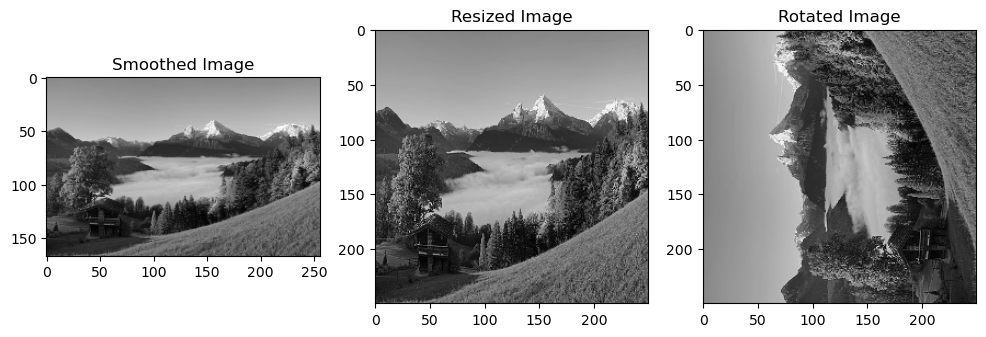

In [75]:
figure4 = plot.figure(2, figsize=(12,12))

subplot_4 = plot.subplot(1,3,1)
plot.imshow(smoothed_image, cmap="gray")
subplot_4.set_title("Smoothed Image")

subplot_4 = plot.subplot(1,3,2)
plot.imshow(resized_image, cmap=plot.cm.gray)
subplot_4.set_title("Resized Image")

subplot_4 = plot.subplot(1,3,3)
plot.imshow(rotated_image, cmap=plot.cm.gray)
subplot_4.set_title("Rotated Image")

The first, out of the three images presented, is the smoothed-edge image. We are able to smooth the hard edges of an image by anti-aliasing. Anti-aliasing smoothes the jagged edges by softening the color transition between edge pixels and background pixels. Because only the edge pixels change, no detail is lost. 
The second image is the resized one. By observing the previous plots we can see that the image scale is bigger, so in this step we have accomplished downscaling. Downscaling means making our image smaller by lowering its resolution. This also reduces detail but in a more predictable way. When downscaling an image, all the information gets crammed into fewer pixels, and since they have to share that space, they get merged together, losing some detail in the process. 
As for the last photo, it is the same resized photo rotated 90 degrees counterclockwise. 

In order to add Gaussian Noise to the image we will use the below Gaussian Noise Function

In [76]:
def gaussian_noise(img,std):
    mean = 0.0   # some constant
    noisy_img = img + np.random.normal(mean, std, img.shape)
    noisy_img_clipped = np.clip(noisy_img, 0, 255)
    noisy_img_clipped = np.around(noisy_img_clipped) 
    noisy_img_clipped = np.asarray(noisy_img_clipped, dtype=np.uint8)
    
    return noisy_img_clipped

In [77]:
#adding the gauss noise to the normalized grayscale image (std=45)
gaussian_image = gaussian_noise(normalized_grayscale_image, 45)

There are many ways we can use in order to reduce the noise of the image. Here we will achieve that by creating a 5x5 median filter. 

In [78]:
#creating a 5X5 median filter 

median_filter = np.ones((5, 5))

# Creating a copy of the noisy image to store the filtered result
median_filter_image = gaussian_image.copy()

# Getting the dimensions of the image
(h, w) = gaussian_image.shape[:2]

# Sliding the filter across the image and applying the 5x5 median filter
for i in range(3, h-3):
    for y in range(3, w-3):
        window = gaussian_image[i-3:i+4, y-3:y+4]
        median_filter_image[i, y] = np.median(window)

Text(0.5, 1.0, 'Image after applying the Median Filter')

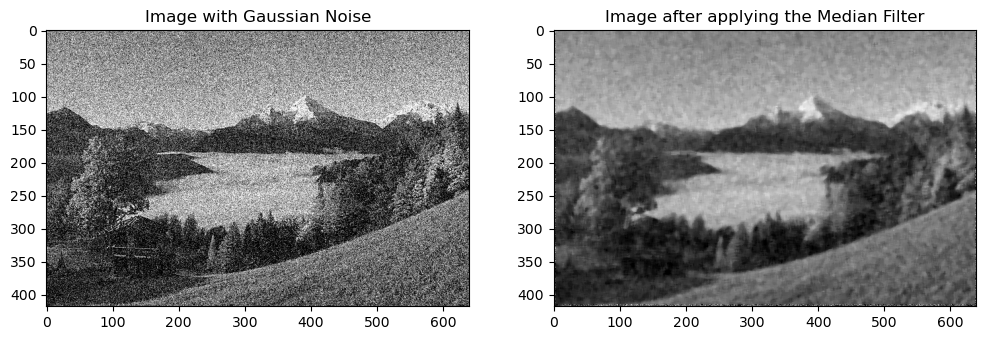

In [79]:
#plotting the image before and after applying the median filter 

figure5 = plot.figure(2, figsize=(12,12))

subplot_5 = plot.subplot(1,2,1)
plot.imshow(gaussian_image, cmap="gray")
subplot_5.set_title("Image with Gaussian Noise")

subplot_5 = plot.subplot(1,2,2)
plot.imshow(median_filter_image, cmap=plot.cm.gray)
subplot_5.set_title("Image after applying the Median Filter")

The first image plotted is the normalized grayscale image with the gaussian noise that we've added. Gaussian noise is a kind of signal noise that has a probability density function equal to that of the normal distribution. Our main goal at this point is to reduce the noise that we've added. Therefore, we are able to achieve that by creating a 5x5 medial filter. After, creating the filter and applying it to the noisy image we continue with plotting the filtered image. In this filtered image we are able to see that the noise has been decreased (still noticeable though) but the outcome is blurry with less details that the original grayscale image. 

In [80]:
#Reading the second image

new_image = image.imread('noise_world_map.png') 

In [81]:
new_image.shape

(434, 654, 4)

With the command .shape we are able to see the image's shape values. We can see here that we have a 4-channel PNG. We would like to keep only the first three channels so in order to do that we have to use the command [:,:,:3]. 

In [82]:
#reading the image again and keeping only the first 3 channels (extracting the last channel's value).
new_image = image.imread('noise_world_map.png')[:,:,:3] 

In [83]:
new_image.shape

(434, 654, 3)

we can see that we have elliminated the last channel's value and we have now a 3-channel PNG image. 

Regarding the step in which we have to locate the outline by using the 4 neighbors adjacency we have to follow before the next mandatory steps.
Firstly, we have to generate the original image into a grayscale one and later on into binary. That's because threshold_otsu is expected to work correctly only for grayscale images so we are converting the normalized grayscale image into binary. After applying the threshold we have to convert the image to integer, fill out the empty spaces and holes of the image and lastly feel boolean image to integers. 

In [84]:

#converting the above original image to grayscale 
Grayscale__image2 = rgb2gray(new_image) # scikit image function

# Greyscale Image Normalization
normalized_grayscale_image2 = (Grayscale__image2 * 255).round().astype(np.uint8)

#converting the image to binary

# Generate otsu threshold
thresh2 = threshold_otsu(normalized_grayscale_image2)
# Apply threshold
Binary_image2 = normalized_grayscale_image2 > thresh2
# Convert to integer
Binary_image2=Binary_image2.astype(int)

#filling empty spaces and holes in the image
Binary_image2=scipy.ndimage.binary_fill_holes(Binary_image2)

# Fill boolean image to integers
Binary_image2=Binary_image2.astype(int)

In [85]:
#applying the 4 neighbors adjacency into the binary image we just created 

[Labeled_image_4,num_of_neighbors_4] = measure.label(Binary_image2, connectivity=1,background=False,return_num=True) 

Text(0.5, 1.0, 'Image outline using the 4 neighbor adjacency')

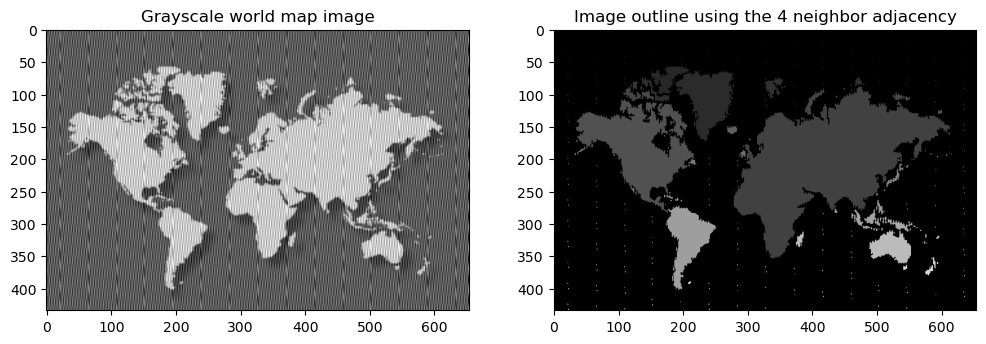

In [86]:
figure6 = plot.figure(2, figsize=(12,12))

subplot_6 = plot.subplot(1,2,1)
plot.imshow(Grayscale__image2, cmap="gray")
subplot_6.set_title("Grayscale world map image")

subplot_6 = plot.subplot(1,2,2)
plot.imshow(Labeled_image_4, cmap=plot.cm.gray)
subplot_6.set_title("Image outline using the 4 neighbor adjacency")

After plotting the original grayscale image as well as the image's outline we can see that we got the desired outcome of the outline. We have to note though that we also got some white spots around the black area of the world map probably because the initial image is noisy and therefore some noise managed to get through. 

Butterworth Low Pass Filter

In [87]:
columns=len(gaussian_image)
rows=len(gaussian_image[0])

wm_vertical = np.linspace(-127, 128, rows)
wm_horizontal = np.linspace(-127, 128, columns)

wm_x,wm_y = np.meshgrid(wm_vertical, wm_horizontal)

wm_distance = np.sqrt(np.power(wm_x,2) + np.power(wm_y,2))

wm_image_DFT = np.fft.fft2(gaussian_image)
wm_Image_Centered_DFT = np.fft.fftshift(wm_image_DFT)

#here we are going to use the code-tools from the file that was given to the precious lab 
wm_Image_Centered_DFT_normalized = np.log(1 + np.abs(wm_Image_Centered_DFT))
wm_Image_Centered_DFT_Final = tools.float_to_uint8(wm_Image_Centered_DFT_normalized)

Now we are going to apply different values for the filter's class and base in order to achieve the best image results out of it. 

case: we set base=15 and n=1

In [88]:
n1=1
base1=15
wm_threshold_n1 = 1 / (1+(np.power(wm_distance,2*n1) / np.power(base1,2*n1)))

wm_mask_circle_n_1 = wm_threshold_n1 * wm_Image_Centered_DFT
wm_mask_circle_normalized_n_1 = np.log( 1 + np.abs(wm_mask_circle_n_1))
wm_mask_circle_final_n_1 = tools.float_to_uint8(wm_mask_circle_normalized_n_1)


wm_Filtered_image_n_1 = np.fft.ifft2(wm_mask_circle_n_1)
wm_Filtered_image_normalized_n_1 = np.abs(wm_Filtered_image_n_1)
wm_Filtered_image_final_n_1 = tools.float_to_float64(wm_Filtered_image_normalized_n_1)

after trying out different values we have come to the conclusion that a butterworth filter with class value = 1 and base value = 15 gives very good image outcome. 

Text(0.5, 1.0, 'Image with Butterworth filter')

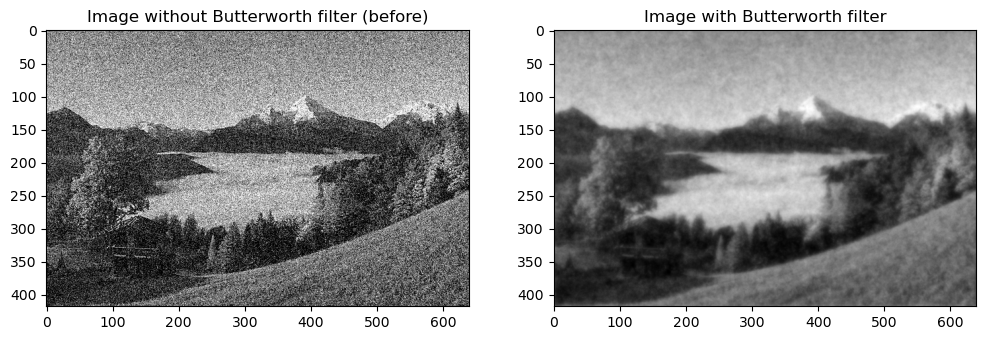

In [89]:
#plotting the image before and after applying the butterworth filter 

figure7 = plot.figure(2, figsize=(12,12))

subplot_7 = plot.subplot(1,2,1)
plot.imshow(gaussian_image, cmap="gray")
subplot_7.set_title("Image without Butterworth filter (before)")

subplot_7 = plot.subplot(1,2,2)
plot.imshow(wm_Filtered_image_final_n_1, cmap=plot.cm.gray)
subplot_7.set_title("Image with Butterworth filter")

Comparing the two filters we applied to the image, the 5x5 median filter and the butterworth filter, we would say that the Butterworth Low Pass filter has a better effect on a noisy image. Even though its application has blurred the final image we notice that several details are visible and furthermore the noise in the original image has been significantly reduced.

In [90]:
#reading the third image
image3 = image.imread('mitosis.jpg')
image3= np.asarray(image3, dtype = np.float64 )

The given image is already in grayscale so we do not need to transform it any further. Sobel edge detector is a gradient based method based on the first order derivatives. It calculates the first derivatives of the image separately for the X and Y axes. 

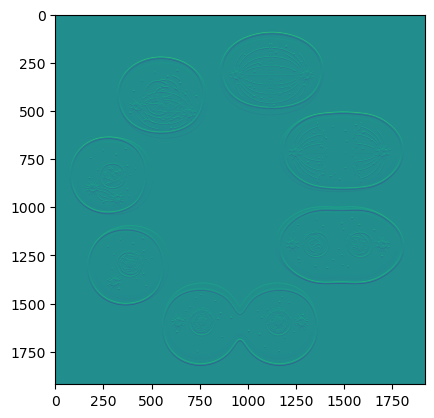

In [91]:
# first we find the horizontal derivative
Image_Gradient_x = scipy.ndimage.sobel(image3, 0)  
plot.imshow(Image_Gradient_x)

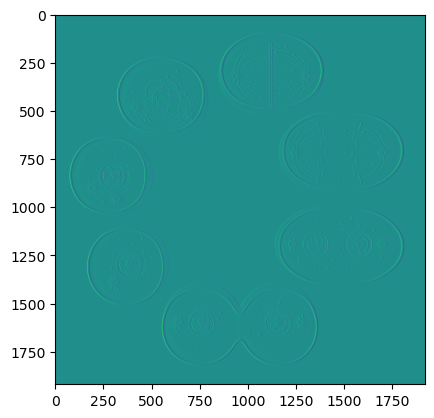

In [92]:
#second step is to find the vertical derivative
Image_Gradient_y = scipy.ndimage.sobel(image3, 1) 
plot.imshow(Image_Gradient_y)

In [93]:
#the third step is to combine the horizontal and vertical derivative

# Given the "legs" of a right triangle, return its hypotenuse
Image_Magnitude = np.hypot(Image_Gradient_x, Image_Gradient_y)  
# normalize the image
Image_Magnitude *= 255.0 / np.max(Image_Magnitude)  

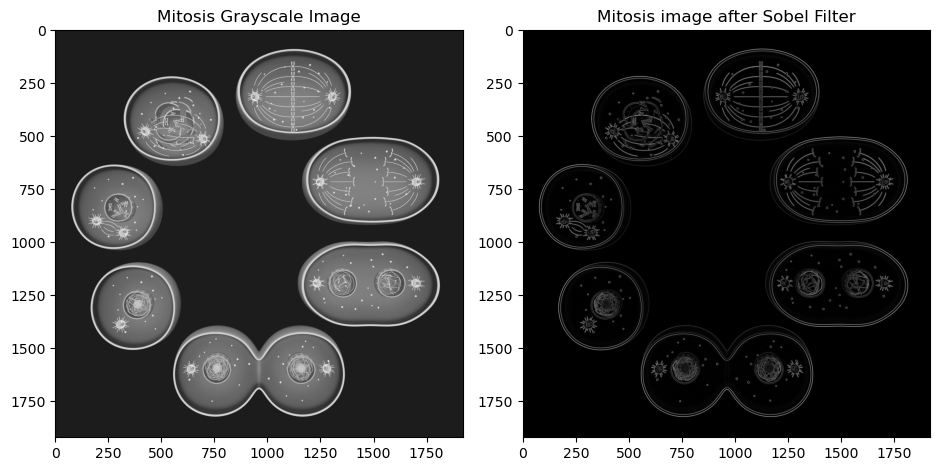

In [94]:
figure10=plot.figure(5, figsize=(9.5, 9.5))

subplot10=figure10.add_subplot(1,2,1)
plot.imshow(image3,cmap="gray")
subplot10.set_title('Mitosis Grayscale Image')

subplot10=figure10.add_subplot(1,2,2)
plot.imshow(Image_Magnitude,cmap="gray")
subplot10.set_title('Mitosis image after Sobel Filter')

figure10.tight_layout()

The last step of this project is to save all the figures into png images  

In [96]:
#saving the figures we created 

figure1.savefig('R,G,B Channels.png')
figure2.savefig('Hue, saturation and value channels.png')
figure3.savefig('From grayscale to binary with threshold application.png')
figure4.savefig('Smoothing, resizing and rotation.png')
figure5.savefig('Noisy image & Median Filter Application.png')
figure6.savefig('Image outline with 4 neighbor adjacency.png')
figure7.savefig('Butterworth Filter Application.png')
figure10.savefig('Edge detection using Sobel Filter.png')